In [23]:
import torch
import numpy as np
import matplotlib.pyplot as plt

In [24]:
pos_embed = torch.zeros((1,64 + 1), dtype=torch.float32) # B, num_patches + 1


print(pos_embed, pos_embed.shape)

tensor([[0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.]]) torch.Size([1, 65])


## Implementing ViT in pytorch
While ready-made implementations exist, this is an attempt to build ViT from scratch using the basic building blocks from pytorch

torch.Size([1, 3, 128, 128])


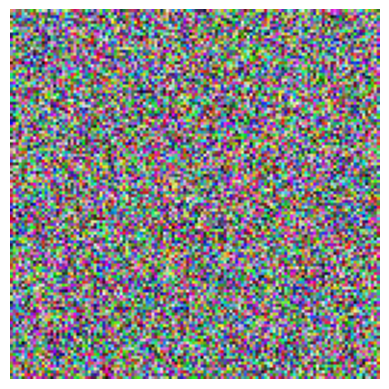

In [25]:
# Image --Patchify--> Patches --Tokenizer--> Tokens --PosEncoding--> Tokens --Embedding--> Embedded vectors --Encoder(self-attn)--> Latent vector --FFN--> Class
image = np.random.randint(0, 255, (128, 128, 3))
image_tensor = torch.tensor(image, dtype=torch.uint8).unsqueeze(0).permute(0,3,1,2)
plt.axis("off")
plt.imshow(image)
print(image_tensor.shape)

In [26]:
# Patchify
device = "cuda" if torch.cuda.is_available() else "cpu"
image_tensor = image_tensor.float() / 255.0
image_tensor.to(device)
patchify = torch.nn.Unfold(16, stride=16)
patches = patchify(image_tensor)
patches = patches.permute(0,2,1) # B, flatten_len, num_patches -> B, num_patches, flatten_len
print(patches.shape, image_tensor.shape, patches.dtype)

torch.Size([1, 64, 768]) torch.Size([1, 3, 128, 128]) torch.float32


In [27]:
# Linear embedding and positional encoding
linear_embed = torch.nn.Linear(768, 767) # Input -> Embed_dim
pos_embed = torch.zeros((1,65), dtype=torch.float32)
pos_embed = torch.arange(0, 65, 1, out=pos_embed, dtype=torch.float32).unsqueeze(2) # (B, pos_embed_size, num_patches)
embedded_patches = linear_embed(patches)
# Add cls_token
cls_token = torch.zeros((1,1,767), dtype=torch.float32)
embedded_patches = torch.concat([cls_token, embedded_patches], dim=1)
print(embedded_patches.shape)
# Append pos_embed
embeddings = torch.concat([embedded_patches, pos_embed], dim=2)
print(embeddings.shape)

torch.Size([1, 65, 767])
torch.Size([1, 65, 768])


In [28]:
from torch.nn import functional as F
from torch import Tensor
from collections.abc import Callable
from typing import Union

class TransformerEncoder(torch.nn.Module):
    def __init__(self, num_layers: int, num_classes: int, embed_dim: int = 768, num_heads=4, norm_first:bool=True, activation: Union[str, Callable[[Tensor], Tensor]] = F.gelu ,*args, **kwargs) -> None:
        super().__init__(*args, **kwargs)
        self.num_classes = num_classes
        self.embed_dim = embed_dim
        layers = [torch.nn.TransformerEncoderLayer(embed_dim, num_heads, batch_first=True, norm_first=norm_first) for _ in range(num_layers)]
        
        self.encoder_blocks = torch.nn.Sequential(*layers)

    def forward(self, x):
        x = self.encoder_blocks(x)
        cls = x[:,0]
        final_layer = torch.nn.Linear(self.embed_dim, self.num_classes)
        out = final_layer(cls)

        return torch.nn.functional.softmax(out, dim = 1)
        
transformer_enc = TransformerEncoder(3, 10)
latent_vec = transformer_enc(embeddings)
print(latent_vec.shape, latent_vec)
transformer_enc

torch.Size([1, 10]) tensor([[0.1509, 0.1713, 0.0844, 0.0885, 0.0534, 0.0410, 0.0909, 0.1170, 0.0642,
         0.1383]], grad_fn=<SoftmaxBackward0>)


TransformerEncoder(
  (encoder_blocks): Sequential(
    (0): TransformerEncoderLayer(
      (self_attn): MultiheadAttention(
        (out_proj): NonDynamicallyQuantizableLinear(in_features=768, out_features=768, bias=True)
      )
      (linear1): Linear(in_features=768, out_features=2048, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
      (linear2): Linear(in_features=2048, out_features=768, bias=True)
      (norm1): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
      (norm2): LayerNorm((768,), eps=1e-05, elementwise_affine=True)
      (dropout1): Dropout(p=0.1, inplace=False)
      (dropout2): Dropout(p=0.1, inplace=False)
    )
    (1): TransformerEncoderLayer(
      (self_attn): MultiheadAttention(
        (out_proj): NonDynamicallyQuantizableLinear(in_features=768, out_features=768, bias=True)
      )
      (linear1): Linear(in_features=768, out_features=2048, bias=True)
      (dropout): Dropout(p=0.1, inplace=False)
      (linear2): Linear(in_features=2048, o

We can go one step finer and use `torch.nn.MultiHeadAttention` or go even further and implement attention layers as well. But let us first clean up the current implementation into a single class and check its performance on MNIST.

In [ ]:
class ViT(torch.nn.Module):
    def __init__(self, num_layers: int, num_classes: int, embed_dim: int = 768, num_heads: int =12, input_shape: tuple = (3, 224, 224), patch_size: int = 16, norm_first:bool=True, activation: Union[str, Callable[[Tensor], Tensor]] = F.gelu, *args, **kwargs) -> None:
        super().__init__(*args, **kwargs)
        self.num_layers = num_layers
        self.num_classes = num_classes
        self.embed_dim = embed_dim
        self.num_heads = num_heads
        self.input_shape = input_shape
        if len(self.input_shape) != 3:
            raise ValueError(f"Input shape {self.input_shape} must be a tuple of length 3 (C, H, W).")
        self.patch_size = patch_size

        # Check if input_shape is divisible by patch_size
        if self.input_shape[1] % self.patch_size != 0 or self.input_shape[2] % self.patch_size != 0:
            raise ValueError(f"Input shape {self.input_shape} is not divisible by patch size {self.patch_size}.")

        self.patchify = torch.nn.Unfold(patch_size, stride=patch_size)
        self.num_patches = (self.input_shape[1] // self.patch_size) * (self.input_shape[2] // self.patch_size)
        self.linear_embed = torch.nn.Linear(self.patch_size**2 * self.input_shape[0], self.embed_dim) # Input (flattened_patch) -> Embed_dim

        # positional embedding for cls_token + num_patches
        self.pos_embed = torch.nn.parameter.Parameter(torch.rand((self.num_patches + 1, self.embed_dim), dtype=torch.float32)) # num_patches + 1, embed_dim
        torch.nn.init.normal_(self.pos_embed, mean=0.0, std=0.02)
        self.layers = torch.nn.ModuleList([torch.nn.TransformerEncoderLayer(self.embed_dim, self.num_heads, activation=activation, norm_first=norm_first, batch_first=True) for _ in range(self.num_layers)])
        # Add cls_token
        self.cls_token = torch.nn.parameter.Parameter(torch.rand((1, 1, self.embed_dim), dtype=torch.float32))
        torch.nn.init.normal_(self.cls_token, mean=0.0, std=0.02)

        self.last_layer = torch.nn.Linear(self.embed_dim, self.num_classes)

    def embed(self, img):
        if img.shape[1:] != self.input_shape:
            raise ValueError(f"Input image shape {img.shape} does not match expected shape {(1, *self.input_shape)}.")
        patches = self.patchify(img)
        patches = patches.permute(0,2,1) # B, flatten_len, num_patches -> B, num_patches, flatten_len
        embedded_patches = self.linear_embed(patches) # B, num_patches, flatten_len -> B, num_patches, embed_dim
        embedded_patches = torch.concat([self.cls_token.expand(patches.shape[0], 1, -1), embedded_patches], dim=1) # B, num_patches + 1, embed_dim
        embeddings = embedded_patches + self.pos_embed
        return embeddings
    
    def forward(self, x):
        x = self.embed(x)
        for i in range(self.num_layers):
            x = self.layers[i](x)
        cls = x[:, 0]
        out = self.last_layer(cls)
        return out

model = ViT(num_layers=4, num_classes=10, input_shape=(3, 128, 128), patch_size=16)
model.to(device=device)
image_tensor.to(device=device)
print(image_tensor.shape, image_tensor.device)
out = model(image_tensor)

        

torch.Size([1, 3, 128, 128]) cuda:0
torch.Size([1, 64, 768]) torch.Size([65, 768])
tensor([[0.0460, 0.1538, 0.0780, 0.0976, 0.0606, 0.0715, 0.1412, 0.1391, 0.0989,
         0.1132]], device='cuda:0', grad_fn=<SoftmaxBackward0>)
